# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** Thariq Fadhlurrahman  
**NIM:** 202310370311299  
**Username GitHub:** Wickleyy

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [5]:
from pathlib import Path

import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

# Ganti dengan path dataset bersih Anda (CSV atau Parquet)
# path_data = "data/processed/dataset_bersih.parquet"
# df = pl.read_parquet(path_data)
# print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dataset_bersih.parquet"
FIG_DIR = PROJECT_ROOT / "output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Jalankan 02_data_cleaning.ipynb dulu. Tidak ditemukan: {DATA_PATH}")

lf = pl.scan_parquet(DATA_PATH)
nama_kolom = lf.collect_schema().names()

KOLOM_PAKAI = [
    "year", "product_type", "province_of_production", "kabupaten_of_production",
    "mill", "exporter_group", "country_of_first_import", "economic_bloc",
    "volume", "fob", "oil_palm_ha",
    "palm_oil_deforestation_annual_exposure",
    "palm_oil_deforestation_10_year_total_exposure",
    "total_emission_exposure", "net_emission_luc_exposure",
    "emission_subsidence_exposure", "gross_emission_luc_exposure",
    "emissions_fire_on_peat_exposure",
]
if "volume_raw" in nama_kolom:
    KOLOM_PAKAI.append("volume_raw")

df = lf.select(KOLOM_PAKAI).collect()
df = df.with_columns(
    pl.col(c).fill_null("TIDAK DIKETAHUI")
    for c in ["province_of_production", "kabupaten_of_production", "exporter_group",
              "country_of_first_import", "economic_bloc"]
)
print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")

# Kolom volume untuk agregasi (lihat catatan di bawah)
VOL = "volume_raw" if "volume_raw" in df.columns else "volume"
print("Kolom volume yang dipakai:", VOL)

def P(frame):
    """Polars -> dict of lists (diterima Plotly Express, tanpa butuh pandas/pyarrow)."""
    return frame.to_dict(as_series=False)


Data loaded: 1,694,907 baris x 18 kolom
Kolom volume yang dipakai: volume


In [6]:
if VOL == "volume":
    batas = df["volume"].max()
    n_cap = df.filter(pl.col("volume") >= batas - 1e-9).height
    print(f"PERINGATAN: memakai volume ter-clip. {n_cap:,} baris ({n_cap/df.height:.1%}) berada tepat di batas {batas:.2f}.")
    print("Total volume pada analisis di bawah adalah batas bawah (underestimate).")
else:
    print("Memakai volume asli (volume_raw): total volume tidak terdistorsi clipping.")

display(df.select(VOL).describe())

PERINGATAN: memakai volume ter-clip. 281,597 baris (16.6%) berada tepat di batas 52.81.
Total volume pada analisis di bawah adalah batas bawah (underestimate).


statistic,volume
str,f64
"""count""",1.694907e6
"""null_count""",0.0
"""mean""",13.886679
"""std""",19.978875
"""min""",5.0414e-11
"""25%""",0.152118
"""50%""",2.12001
"""75%""",21.216855
"""max""",52.813961


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions)
untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

**Waspadai:** jumlah baris per tahun sangat timpang. 2013–2017 hanya ±2.000 baris/tahun, sedangkan 2018 melonjak ke 247.986 baris dan 2020 mencapai 448.728. Lonjakan itu kemungkinan perubahan granularitas pencatatan, bukan lonjakan aktivitas. Karena itu tren dibaca dari **total volume**, bukan dari jumlah baris.

In [7]:
# Contoh penerapan temporal operations pada Polars:
# 1. Downsampling ke interval tertentu (misal: per jam / per hari)
# df_temporal = df.sort("timestamp").group_by_dynamic("timestamp", every="1d").agg([...])
#
# 2. Rata-rata bergerak (moving average)
# df_rolling = df.with_columns(pl.col("nilai").rolling_mean(window_size=7).alias("ma_7"))

# 2.1 Agregat tahunan + shift (YoY) + rolling_mean (MA 3 tahun) di Polars
tahunan = (
    df.group_by("year")
    .agg(
        pl.col(VOL).sum().alias("volume_total"),
        pl.col("fob").sum().alias("fob_total"),
        pl.len().alias("n_baris"),
        pl.col("mill").n_unique().alias("n_mill"),
        pl.col("province_of_production").n_unique().alias("n_provinsi"),
    )
    .sort("year")
    .with_columns(
        pl.col("volume_total").shift(1).alias("volume_tahun_lalu"),
        pl.col("volume_total").rolling_mean(window_size=3).alias("volume_ma3"),
    )
    .with_columns(
        ((pl.col("volume_total") / pl.col("volume_tahun_lalu") - 1) * 100).alias("yoy_pct")
    )
)
display(tahunan)

year,volume_total,fob_total,n_baris,n_mill,n_provinsi,volume_tahun_lalu,volume_ma3,yoy_pct
i64,f64,f64,u32,u32,u32,f64,f64,f64
2013,103063.783244,0.0,2095,1,1,null,null,null
2014,101288.953504,0.0,2056,1,1,103063.783244,null,-1.722069
2015,100836.728052,0.0,2038,1,1,101288.953504,101729.8216,-0.446471
2016,110260.030754,0.0,2213,1,1,100836.728052,104128.57077,9.34511
2017,92127.918069,0.0,1831,1,1,110260.030754,101074.892292,-16.444865
2018,3.8912e6,3.6599e10,247986,963,25,92127.918069,1.3645e6,4123.677025
2019,4.3126e6,1.2703e10,318343,1011,25,3.8912e6,2.7653e6,10.829213
2020,5.5552e6,1.8042e10,448728,1006,25,4.3126e6,4.5863e6,28.814427
2021,5.2937e6,2.6163e10,385389,1048,25,5.5552e6,5.0538e6,-4.706941


In [8]:
# 2.2 Per jenis produk (shift & rolling_mean dengan .over agar tidak bocor antar-grup)
tahunan_produk = (
    df.group_by("year", "product_type")
    .agg(pl.col(VOL).sum().alias("volume_total"), pl.col("fob").sum().alias("fob_total"))
    .sort("product_type", "year")
    .with_columns(
        pl.col("volume_total").rolling_mean(window_size=3).over("product_type").alias("volume_ma3"),
        pl.col("volume_total").shift(1).over("product_type").alias("volume_tahun_lalu"),
    )
    .with_columns(
        ((pl.col("volume_total") / pl.col("volume_tahun_lalu") - 1) * 100).alias("yoy_pct")
    )
)
display(tahunan_produk)

# 2.3 group_by_dynamic pada indeks integer: jendela 3 tahun
jendela_3th = (
    tahunan.select("year", "volume_total", "fob_total")
    .sort("year")
    .group_by_dynamic("year", every="3i", closed="left")
    .agg(
        pl.col("volume_total").sum().alias("volume_3th"),
        pl.col("fob_total").sum().alias("fob_3th"),
        pl.len().alias("n_tahun"),
    )
)
display(jendela_3th)

year,product_type,volume_total,fob_total,volume_ma3,volume_tahun_lalu,yoy_pct
i64,str,f64,f64,f64,f64,f64
2013,"""PALM OIL""",103063.783244,0.0,null,null,null
2014,"""PALM OIL""",101288.953504,0.0,null,103063.783244,-1.722069
2015,"""PALM OIL""",100836.728052,0.0,101729.8216,101288.953504,-0.446471
2016,"""PALM OIL""",110260.030754,0.0,104128.57077,100836.728052,9.34511
2017,"""PALM OIL""",92127.918069,0.0,101074.892292,110260.030754,-16.444865
…,…,…,…,…,…,…
2018,"""REFINED PALM OIL""",3.3903e6,3.0114e10,null,null,null
2019,"""REFINED PALM OIL""",3.4625e6,8.7099e9,null,3.3903e6,2.127929
2020,"""REFINED PALM OIL""",4.5553e6,1.2876e10,3.8027e6,3.4625e6,31.563497


year,volume_3th,fob_3th,n_tahun
i64,f64,f64,u32
2013,305189.464801,0.0,3
2016,4.0936e6,3.6599e10,3
2019,1.5162e7,5.6909e10,3
2022,3.9764e6,2.4392e10,1


In [9]:
# 2.4 Window function DuckDB: kumulatif & LAG per produk
con = duckdb.connect()
con.register("tahunan_produk", tahunan_produk.select("year", "product_type", "volume_total"))

window_duckdb = con.execute("""
    SELECT
        year,
        product_type,
        volume_total,
        SUM(volume_total) OVER (PARTITION BY product_type ORDER BY year) AS volume_kumulatif,
        100 * (volume_total / LAG(volume_total) OVER (PARTITION BY product_type ORDER BY year) - 1) AS yoy_pct,
        RANK() OVER (PARTITION BY product_type ORDER BY volume_total DESC) AS peringkat_tahun
    FROM tahunan_produk
    ORDER BY product_type, year
""").pl()
display(window_duckdb)

year,product_type,volume_total,volume_kumulatif,yoy_pct,peringkat_tahun
i64,str,f64,f64,f64,i64
2013,"""PALM OIL""",103063.783244,103063.783244,null,7
2014,"""PALM OIL""",101288.953504,204352.736748,-1.722069,8
2015,"""PALM OIL""",100836.728052,305189.464801,-0.446471,9
2016,"""PALM OIL""",110260.030754,415449.495554,9.34511,6
2017,"""PALM OIL""",92127.918069,507577.413623,-16.444865,10
…,…,…,…,…,…
2018,"""REFINED PALM OIL""",3.3903e6,3.3903e6,null,5
2019,"""REFINED PALM OIL""",3.4625e6,6.8528e6,2.127929,4
2020,"""REFINED PALM OIL""",4.5553e6,1.1408e7,31.563497,2


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

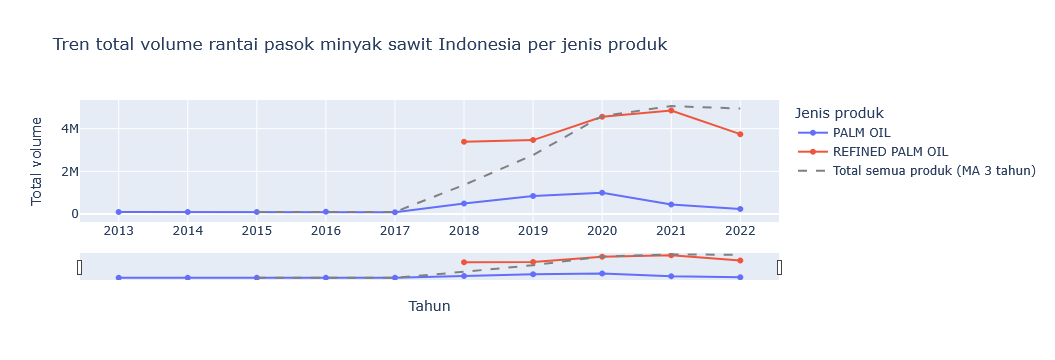

In [10]:
# Visualisasi 1: Tren Waktu Interaktif
# fig1 = px.line(...)
# fig1.show()
# Visualisasi 1: Tren volume per tahun (line chart + range slider + MA 3 tahun)
fig1 = px.line(
    P(tahunan_produk), x="year", y="volume_total", color="product_type", markers=True,
    labels={"year": "Tahun", "volume_total": "Total volume", "product_type": "Jenis produk"},
    title="Tren total volume rantai pasok minyak sawit Indonesia per jenis produk",
)
fig1.add_trace(go.Scatter(
    x=tahunan["year"].to_list(), y=tahunan["volume_ma3"].to_list(),
    mode="lines", name="Total semua produk (MA 3 tahun)", line=dict(dash="dash", color="gray"),
))
fig1.update_xaxes(rangeslider_visible=True, dtick=1)
fig1.update_layout(hovermode="x unified")
fig1.write_html(FIG_DIR / "viz1_tren_volume.html")
fig1.show()

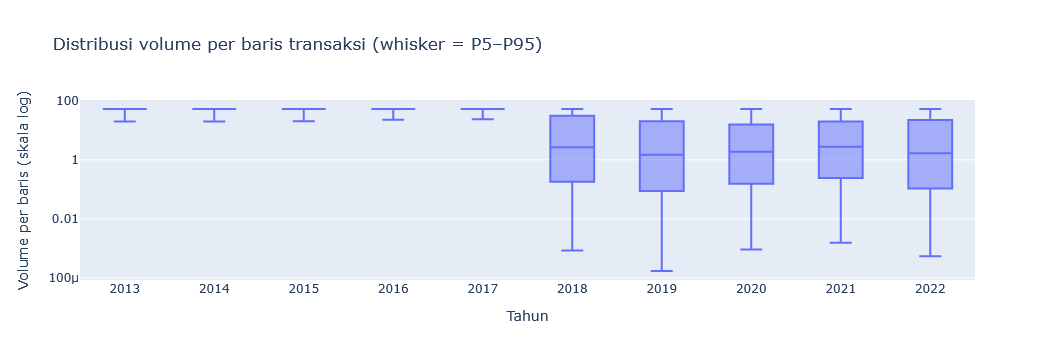

In [11]:
# Visualisasi 2: Distribusi dan Outlier
# fig2 = px.box(...)
# fig2.show()
# Visualisasi 2: Distribusi volume per tahun (box plot dari kuantil, skala log)
kuantil = (
    df.filter(pl.col(VOL) > 0)
    .group_by("year")
    .agg(
        pl.col(VOL).quantile(0.05).alias("p05"),
        pl.col(VOL).quantile(0.25).alias("q1"),
        pl.col(VOL).quantile(0.50).alias("median"),
        pl.col(VOL).quantile(0.75).alias("q3"),
        pl.col(VOL).quantile(0.95).alias("p95"),
    )
    .sort("year")
)
fig2 = go.Figure(go.Box(
    x=[str(y) for y in kuantil["year"].to_list()],
    q1=kuantil["q1"].to_list(), median=kuantil["median"].to_list(), q3=kuantil["q3"].to_list(),
    lowerfence=kuantil["p05"].to_list(), upperfence=kuantil["p95"].to_list(),
    name="Volume per baris",
))
fig2.update_yaxes(type="log", title="Volume per baris (skala log)")
fig2.update_xaxes(title="Tahun")
fig2.update_layout(title="Distribusi volume per baris transaksi (whisker = P5–P95)")
fig2.write_html(FIG_DIR / "viz2_distribusi_volume.html")
fig2.show()

Baris lengkap (tanpa null) untuk korelasi: 669,617 dari 1,694,907


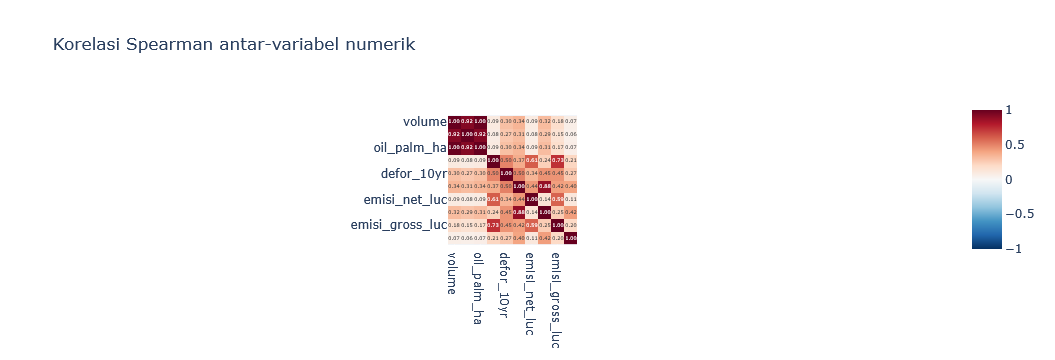

In [12]:
# Visualisasi 3: Korelasi Antar-Variabel
# fig3 = px.imshow(...)
# fig3.show()
# Visualisasi 3: Korelasi Spearman antar-variabel numerik (sampel 200 ribu baris)
kolom_num = [
    VOL, "fob", "oil_palm_ha",
    "palm_oil_deforestation_annual_exposure", "palm_oil_deforestation_10_year_total_exposure",
    "total_emission_exposure", "net_emission_luc_exposure", "emission_subsidence_exposure",
    "gross_emission_luc_exposure", "emissions_fire_on_peat_exposure",
]
label = ["volume", "fob", "oil_palm_ha", "defor_annual", "defor_10yr",
         "emisi_total", "emisi_net_luc", "emisi_subsidence", "emisi_gross_luc", "emisi_api_gambut"]

num = df.select(kolom_num).drop_nulls()
print(f"Baris lengkap (tanpa null) untuk korelasi: {num.height:,} dari {df.height:,}")
if num.height > 200_000:
    num = num.sample(200_000, seed=42)

pasangan = {
    (i, j): pl.corr(kolom_num[i], kolom_num[j], method="spearman").alias(f"{i}_{j}")
    for i in range(len(kolom_num)) for j in range(i + 1, len(kolom_num))
}
hasil = num.select(list(pasangan.values())).row(0)

n = len(kolom_num)
matriks = [[1.0 if i == j else None for j in range(n)] for i in range(n)]
for ((i, j), _), nilai in zip(pasangan.items(), hasil):
    matriks[i][j] = matriks[j][i] = nilai

fig3 = px.imshow(
    matriks, x=label, y=label, zmin=-1, zmax=1, color_continuous_scale="RdBu_r",
    text_auto=".2f", title="Korelasi Spearman antar-variabel numerik",
)
fig3.write_html(FIG_DIR / "viz3_korelasi.html")
fig3.show()

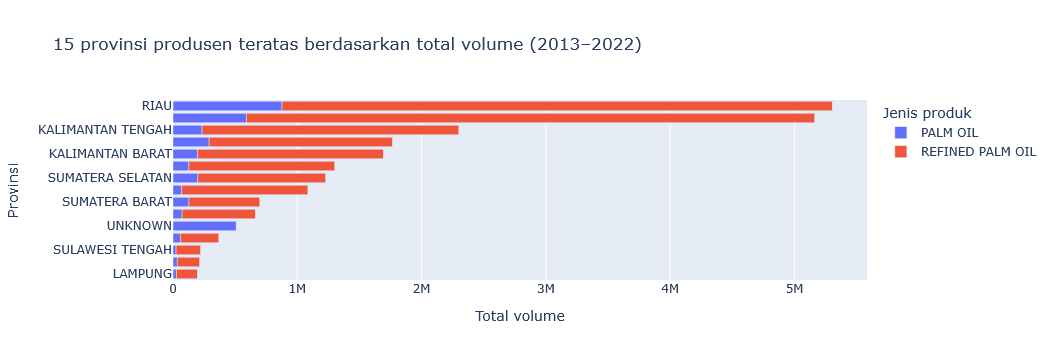

In [13]:
# Visualisasi 4: Komposisi Kategori
# fig4 = px.bar(...)
# fig4.show()
# Visualisasi 4: Komposisi volume per provinsi (15 teratas) per jenis produk
prov_total = (
    df.group_by("province_of_production").agg(pl.col(VOL).sum().alias("volume_total"))
    .sort("volume_total", descending=True)
)
top15 = prov_total.head(15)["province_of_production"].to_list()

prov_produk = (
    df.filter(pl.col("province_of_production").is_in(top15))
    .group_by("province_of_production", "product_type")
    .agg(pl.col(VOL).sum().alias("volume_total"))
)
fig4 = px.bar(
    P(prov_produk), x="volume_total", y="province_of_production", color="product_type",
    orientation="h",
    labels={"volume_total": "Total volume", "province_of_production": "Provinsi", "product_type": "Jenis produk"},
    title="15 provinsi produsen teratas berdasarkan total volume (2013–2022)",
)
fig4.update_yaxes(categoryorder="total ascending")
fig4.write_html(FIG_DIR / "viz4_komposisi_provinsi.html")
fig4.show()

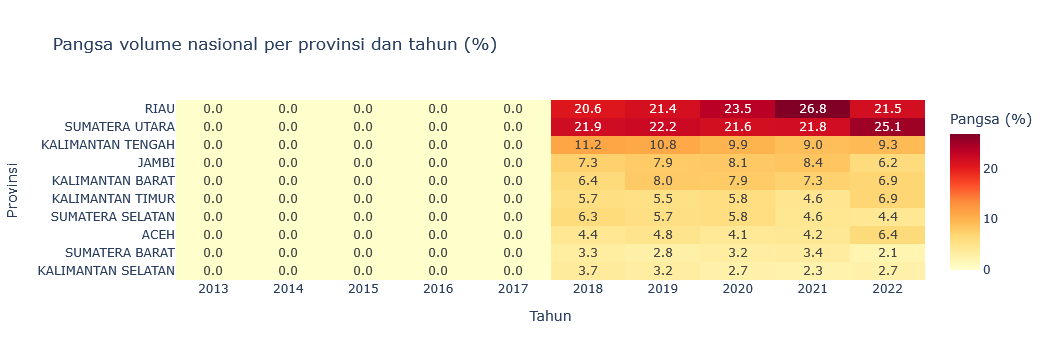

In [14]:
# Visualisasi 5: Siklus Musiman / Pola Temporal Berkala
# fig5 = px.density_heatmap(...)
# fig5.show()
# Visualisasi 5: Pola temporal-spasial berkala: pangsa nasional 10 provinsi teratas per tahun (heatmap)
top10 = top15[:10]
total_tahun = {r["year"]: r["volume_total"] for r in tahunan.select("year", "volume_total").to_dicts()}

pangsa = (
    df.filter(pl.col("province_of_production").is_in(top10))
    .group_by("year", "province_of_production")
    .agg(pl.col(VOL).sum().alias("v"))
)
lookup = {(r["province_of_production"], r["year"]): r["v"] for r in pangsa.to_dicts()}
tahun_list = sorted(total_tahun)

z = [[100 * lookup.get((p, y), 0) / total_tahun[y] for y in tahun_list] for p in top10]
fig5 = px.imshow(
    z, x=[str(y) for y in tahun_list], y=top10, color_continuous_scale="YlOrRd", text_auto=".1f",
    labels=dict(x="Tahun", y="Provinsi", color="Pangsa (%)"),
    title="Pangsa volume nasional per provinsi dan tahun (%)", aspect="auto",
)
fig5.write_html(FIG_DIR / "viz5_pangsa_provinsi_tahun.html")
fig5.show()

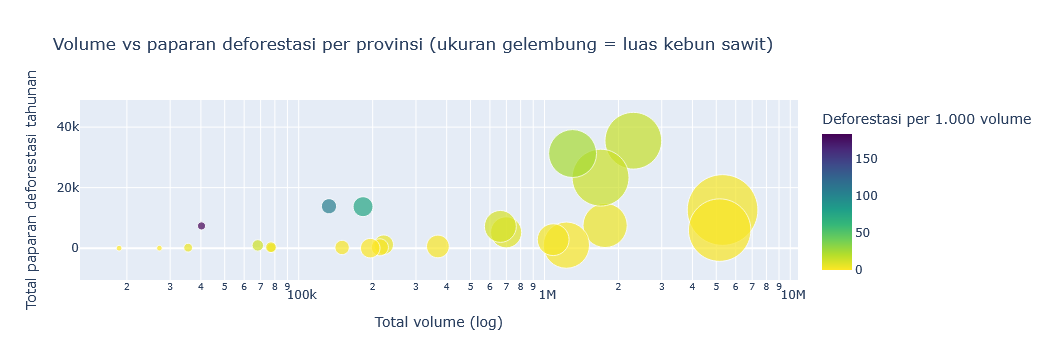

In [15]:
# Visualisasi 6: Analisis Lanjutan / Spasial
# fig6 = px.scatter_geo(...)
# fig6.show()
# Visualisasi 6: Multi-dimensi per provinsi: volume vs paparan deforestasi (bubble)
prov_multi = (
    df.group_by("province_of_production")
    .agg(
        pl.col(VOL).sum().alias("volume_total"),
        pl.col("palm_oil_deforestation_annual_exposure").sum().alias("defor_annual_total"),
        pl.col("oil_palm_ha").sum().alias("oil_palm_ha_total"),
        pl.col("mill").n_unique().alias("n_mill"),
    )
    .filter(pl.col("volume_total") > 0)
    .with_columns((pl.col("defor_annual_total") / pl.col("volume_total") * 1000).alias("defor_per_1000_vol"))
    .sort("volume_total", descending=True)
    .head(25)
    .with_columns(pl.col("oil_palm_ha_total").fill_null(0) + 1)  # size Plotly harus > 0
)
fig6 = px.scatter(
    P(prov_multi), x="volume_total", y="defor_annual_total", size="oil_palm_ha_total",
    color="defor_per_1000_vol", hover_name="province_of_production",
    hover_data=["n_mill"], log_x=True, color_continuous_scale="Viridis_r", size_max=50,
    labels={
        "volume_total": "Total volume (log)", "defor_annual_total": "Total paparan deforestasi tahunan",
        "defor_per_1000_vol": "Deforestasi per 1.000 volume",
    },
    title="Volume vs paparan deforestasi per provinsi (ukuran gelembung = luas kebun sawit)",
)
fig6.write_html(FIG_DIR / "viz6_volume_vs_deforestasi.html")
fig6.show()

## Bagian 4: Rumusan 5 Insight Analitik Utama

Tuliskan minimal 5 temuan atau wawasan penting yang Anda peroleh dari visualisasi di atas:

1. **Insight 1 (Tren Waktu & Musiman):**  
   [Jelaskan temuan terkait tren jangka panjang atau pola berulang yang teridentifikasi]

2. **Insight 2 (Distribusi & Anomali):**  
   [Jelaskan temuan terkait sebaran data, ketimpangan, atau keberadaan pencilan penting]

3. **Insight 3 (Korelasi Kunci):**  
   [Jelaskan hubungan signifikan antar-variabel yang dapat dijadikan dasar keputusan bisnis/kebijakan]

4. **Insight 4 (Perilaku Kategori / Segmen):**  
   [Jelaskan perbedaan karakteristik performa antar kelompok/wilayah/kategori produk]

5. **Insight 5 (Rekomendasi Praktis):**  
   [Jelaskan tindakan nyata atau strategi operasional yang direkomendasikan berdasarkan seluruh temuan di atas]


In [16]:
print("=== INSIGHT 1: Tren ===")
awal, akhir = tahunan.row(0, named=True), tahunan.row(-1, named=True)
n_th = akhir["year"] - awal["year"]
cagr = (akhir["volume_total"] / awal["volume_total"]) ** (1 / n_th) - 1
puncak = tahunan.sort("volume_total", descending=True).row(0, named=True)
yoy_max = tahunan.drop_nulls("yoy_pct").sort("yoy_pct", descending=True).row(0, named=True)
yoy_min = tahunan.drop_nulls("yoy_pct").sort("yoy_pct").row(0, named=True)
print(f"CAGR volume {awal['year']}-{akhir['year']}: {cagr:.2%}")
print(f"Puncak volume: {puncak['year']} ({puncak['volume_total']:,.0f})")
print(f"YoY tertinggi: {yoy_max['year']} ({yoy_max['yoy_pct']:.1f}%) | terendah: {yoy_min['year']} ({yoy_min['yoy_pct']:.1f}%)")

print("\n=== INSIGHT 2: Distribusi ===")
p = df.filter(pl.col(VOL) > 0).select(
    pl.col(VOL).median().alias("median"),
    pl.col(VOL).mean().alias("mean"),
    pl.col(VOL).quantile(0.99).alias("p99"),
    pl.col(VOL).max().alias("max"),
).row(0, named=True)
print({k: round(v, 2) for k, v in p.items()})
vol_sorted = df.select(pl.col(VOL).sort(descending=True)).to_series()
top1pct = vol_sorted.head(int(len(vol_sorted) * 0.01)).sum() / vol_sorted.sum()
print(f"Pangsa volume dari 1% baris terbesar: {top1pct:.1%}")

print("\n=== INSIGHT 3: Korelasi (Spearman, |r| tertinggi) ===")
daftar = sorted(
    [(abs(matriks[i][j]), label[i], label[j], matriks[i][j])
     for i in range(n) for j in range(i + 1, n) if matriks[i][j] is not None and matriks[i][j] == matriks[i][j]],
    reverse=True,
)
for _, a, b, r in daftar[:6]:
    print(f"{a} ~ {b}: {r:.2f}")
print("(Emisi total adalah penjumlahan komponennya, jadi korelasi tinggi di antaranya wajar dan bukan temuan.)")

print("\n=== INSIGHT 4: Segmen ===")
print("Pangsa volume 3 provinsi teratas:")
for r in prov_total.head(3).with_columns((pl.col("volume_total") / prov_total["volume_total"].sum() * 100).alias("pct")).to_dicts():
    print(f"  {r['province_of_production']}: {r['pct']:.1f}%")
negara = (
    df.group_by("country_of_first_import").agg(pl.col(VOL).sum().alias("v")).sort("v", descending=True)
    .with_columns((pl.col("v") / pl.col("v").sum() * 100).alias("pct")).head(5)
)
print("5 negara tujuan pertama teratas:"); display(negara)
blok = (
    df.group_by("economic_bloc").agg(pl.col(VOL).sum().alias("v")).sort("v", descending=True)
    .with_columns((pl.col("v") / pl.col("v").sum() * 100).alias("pct")).head(5)
)
print("5 blok ekonomi teratas:"); display(blok)

print("\n=== INSIGHT 5: Keberlanjutan (untuk rekomendasi) ===")
display(
    prov_multi.sort("defor_per_1000_vol", descending=True)
    .select("province_of_production", "volume_total", "defor_annual_total", "defor_per_1000_vol")
    .head(5)
)
harga = (
    df.filter(pl.col("fob").is_not_null() & (pl.col(VOL) > 0))
    .group_by("year").agg((pl.col("fob").sum() / pl.col(VOL).sum()).alias("fob_per_volume"))
    .sort("year")
)
display(harga)

=== INSIGHT 1: Tren ===
CAGR volume 2013-2022: 50.06%
Puncak volume: 2020 (5,555,213)
YoY tertinggi: 2018 (4123.7%) | terendah: 2022 (-24.9%)

=== INSIGHT 2: Distribusi ===
{'median': 2.12, 'mean': 13.89, 'p99': 52.81, 'max': 52.81}
Pangsa volume dari 1% baris terbesar: 3.8%

=== INSIGHT 3: Korelasi (Spearman, |r| tertinggi) ===
volume ~ oil_palm_ha: 1.00
fob ~ oil_palm_ha: 0.92
volume ~ fob: 0.92
emisi_total ~ emisi_subsidence: 0.88
defor_annual ~ emisi_gross_luc: 0.73
defor_annual ~ emisi_net_luc: 0.61
(Emisi total adalah penjumlahan komponennya, jadi korelasi tinggi di antaranya wajar dan bukan temuan.)

=== INSIGHT 4: Segmen ===
Pangsa volume 3 provinsi teratas:
  RIAU: 22.5%
  SUMATERA UTARA: 21.9%
  KALIMANTAN TENGAH: 9.8%
5 negara tujuan pertama teratas:


country_of_first_import,v,pct
str,f64,f64
"""INDIA""",2.2808e6,9.690387
"""CHINA (MAINLAND)""",1.7450e6,7.414027
"""PAKISTAN""",1.5040e6,6.389893
"""MALAYSIA""",982040.143399,4.172391
"""BANGLADESH""",875832.54251,3.721147


5 blok ekonomi teratas:


economic_bloc,v,pct
str,f64,f64
"""EUROPEAN UNION""",3.0560e6,12.983859
"""INDIA""",2.2808e6,9.690387
"""CHINA (MAINLAND)""",1.7450e6,7.414027
"""PAKISTAN""",1.5040e6,6.389893
"""MALAYSIA""",982040.143399,4.172391



=== INSIGHT 5: Keberlanjutan (untuk rekomendasi) ===


province_of_production,volume_total,defor_annual_total,defor_per_1000_vol
str,f64,f64,f64
"""PAPUA BARAT""",40241.577112,7347.716021,182.59016
"""PAPUA""",132830.633143,13854.034521,104.29849
"""KALIMANTAN UTARA""",182738.143053,13704.09477,74.993072
"""KALIMANTAN TIMUR""",1.3014e6,31262.848956,24.022594
"""KALIMANTAN TENGAH""",2.2993e6,35498.253718,15.438885


year,fob_per_volume
i64,f64
2018,9434.388023
2019,2953.396338
2020,3254.839384
2021,4942.341612
2022,6134.167829


### Tulis Insight Analitik Utama

**1. Insight 1 (Tren Waktu & Musiman)**

Total volume rantai pasok minyak sawit Indonesia menunjukkan kecenderungan meningkat selama periode 2013–2022, dengan CAGR (Compound Annual Growth Rate) sebesar **50,06%**. Puncak total volume tercatat pada tahun **2020 sebesar 5.555.213**. Pertumbuhan tahunan (YoY) tertinggi terjadi pada **2018 sebesar 4.123,7%**, sedangkan penurunan terbesar terjadi pada **2022 sebesar 24,9%**. Setelah mencapai puncak pada 2020, volume mengalami perubahan pada 2021 dan kembali menurun pada 2022.

Peningkatan yang sangat tajam pada 2018 perlu diinterpretasikan secara hati-hati. Jumlah baris dataset meningkat dari sekitar 2 ribu baris per tahun pada 2013–2017 menjadi 247.986 baris pada 2018. Perubahan ini mengindikasikan adanya kemungkinan perubahan cakupan atau granularitas pencatatan data, sehingga lonjakan volume tidak dapat langsung dianggap sebagai pertumbuhan aktivitas rantai pasok yang sepenuhnya riil. Selain itu, karena data memiliki resolusi tahunan, pola musiman bulanan tidak dapat diidentifikasi.

*(Lihat Visualisasi 1.)*

**2. Insight 2 (Distribusi & Anomali)**

Distribusi volume per baris transaksi menunjukkan karakteristik menceng ke kanan (right-skewed). Hal ini terlihat dari nilai rata-rata sebesar **13,89**, yang jauh lebih tinggi dibandingkan median sebesar **2,12**. Kondisi tersebut menunjukkan bahwa sebagian besar baris transaksi memiliki volume relatif kecil, sementara sejumlah transaksi memiliki volume lebih besar.

Nilai persentil ke-99 (P99) dan maksimum sama-sama sebesar **52,81**. Kesamaan ini berkaitan dengan proses winsorization pada tahap pembersihan data, yaitu pembatasan nilai menggunakan batas atas IQR. Sebanyak **281.597 baris** mengalami perubahan nilai akibat proses tersebut, atau sekitar **16,61% dari total baris**. Meskipun demikian, 1% baris dengan volume terbesar hanya menyumbang sekitar **3,8% dari total volume** pada hasil analisis. Dengan demikian, distribusi volume tidak hanya dipengaruhi oleh beberapa transaksi terbesar, tetapi juga oleh karakteristik sebaran transaksi secara keseluruhan.

*(Lihat Visualisasi 2.)*

**3. Insight 3 (Korelasi Kunci)**

Hasil analisis korelasi Spearman menunjukkan hubungan positif yang sangat kuat antara **volume dan luas kebun sawit (oil_palm_ha)** dengan koefisien korelasi sebesar **0,92** berdasarkan output numerik yang diberikan. Hubungan positif yang kuat juga ditemukan antara **FOB dan luas kebun sawit**, serta antara **volume dan FOB**, masing-masing sebesar **0,92**. Temuan ini mengindikasikan bahwa peningkatan luas kebun sawit dan nilai perdagangan cenderung berkaitan dengan peningkatan volume rantai pasok.

Pada variabel keberlanjutan, korelasi antara paparan deforestasi tahunan dan emisi gross LUC sebesar **0,73**, sedangkan korelasi dengan emisi net LUC sebesar **0,61**. Sementara itu, korelasi emisi total dengan emisi subsidence mencapai **0,88**. Korelasi tinggi antarkomponen emisi perlu ditafsirkan secara hati-hati karena beberapa variabel memiliki hubungan matematis dalam perhitungannya.

Hubungan volume dengan variabel paparan deforestasi dan emisi pada matriks korelasi tidak sekuat hubungan volume dengan luas kebun sawit dan FOB. Oleh karena itu, volume produksi yang tinggi tidak secara otomatis menunjukkan tingkat paparan deforestasi atau emisi yang tinggi. Korelasi juga tidak dapat digunakan untuk menyimpulkan hubungan sebab-akibat.

*(Lihat Visualisasi 3.)*

**4. Insight 4 (Perilaku Kategori / Segmen)**

Distribusi volume berdasarkan wilayah menunjukkan konsentrasi produksi pada beberapa provinsi utama. Tiga provinsi dengan pangsa volume terbesar adalah **Riau sebesar 22,5%**, **Sumatera Utara sebesar 21,9%**, dan **Kalimantan Tengah sebesar 9,8%**. Secara keseluruhan, ketiganya menyumbang sekitar **54,2% dari total volume** yang dianalisis. Hal ini menunjukkan bahwa rantai pasok minyak sawit Indonesia memiliki konsentrasi geografis yang cukup besar pada sejumlah wilayah produsen utama.

Berdasarkan heatmap pangsa volume nasional, Riau mempertahankan posisi sebagai salah satu kontributor utama dengan pangsa sebesar **20,6% pada 2018**, meningkat hingga **26,8% pada 2021**, kemudian turun menjadi **21,5% pada 2022**. Sementara itu, Sumatera Utara memiliki pangsa yang relatif stabil, yaitu sekitar **21,6–22,2% pada 2018–2021**, sebelum meningkat menjadi **25,1% pada 2022**. Perubahan ini menunjukkan adanya pergeseran kontribusi relatif antarprovinsi dari tahun ke tahun.

Dari sisi tujuan perdagangan, India merupakan negara tujuan pertama terbesar dengan volume sekitar **2,28 juta** atau **9,69%**. Selanjutnya terdapat China (Mainland) sebesar **7,41%**, Pakistan sebesar **6,39%**, Malaysia sebesar **4,17%**, dan Bangladesh sebesar **3,72%**. Jika dikelompokkan berdasarkan blok ekonomi, European Union menempati posisi teratas dengan pangsa **12,98%**.

*(Lihat Visualisasi 4 dan 5.)*

**5. Insight 5 (Rekomendasi Praktis)**

Analisis hubungan volume dan paparan deforestasi tahunan per satuan volume menunjukkan bahwa beberapa provinsi memiliki tingkat paparan relatif tinggi meskipun volume rantai pasoknya tidak sebesar provinsi produsen utama. **Papua Barat** memiliki rasio paparan deforestasi tertinggi sebesar **182,59 per 1.000 volume**, diikuti **Papua sebesar 104,30** dan **Kalimantan Utara sebesar 74,99**. Sebaliknya, Kalimantan Tengah memiliki rasio sebesar **15,44 per 1.000 volume**, meskipun total volume dan paparan deforestasi absolutnya relatif besar.

Temuan ini menunjukkan bahwa prioritas pemantauan keberlanjutan tidak sebaiknya hanya ditentukan berdasarkan besarnya volume produksi. Rasio paparan deforestasi terhadap volume juga perlu diperhatikan agar wilayah dengan tingkat paparan relatif tinggi tidak terabaikan.

Rekomendasi praktis yang dapat diterapkan adalah memprioritaskan verifikasi dan penelusuran rantai pasok pada wilayah dengan rasio paparan deforestasi tinggi, khususnya Papua Barat, Papua, dan Kalimantan Utara. Selain itu, pemantauan terhadap mill dan kelompok perusahaan yang beroperasi di wilayah tersebut dapat ditingkatkan untuk mendukung transparansi rantai pasok. Untuk wilayah dengan volume besar seperti Riau, Sumatera Utara, dan Kalimantan Tengah, pengawasan tetap diperlukan karena kontribusinya yang besar terhadap total rantai pasok nasional.

Rekomendasi tersebut perlu mempertimbangkan keterbatasan data, khususnya karena nilai emisi tidak tersedia pada sebagian besar baris dataset dan hasil rasio paparan tidak secara langsung membuktikan terjadinya deforestasi akibat aktivitas produksi tertentu.

*(Lihat Visualisasi 6.)*

---

### Keterbatasan Data

1. **Missing values pada variabel emisi:** Lima kolom emisi memiliki nilai kosong pada 1.025.290 baris atau sekitar 60,49% dari keseluruhan data. Pola kekosongan tersebut bersifat terstruktur, yaitu seluruh data periode 2013–2020 tidak memiliki nilai emisi, sedangkan periode 2021–2022 tersedia. Oleh karena itu, analisis emisi hanya merepresentasikan subset data yang tersedia dan tidak dapat digeneralisasikan secara langsung untuk seluruh periode.

2. **Winsorization pada volume:** Sebanyak 281.597 baris mengalami pembatasan nilai volume menggunakan metode IQR. Dengan demikian, analisis distribusi dan statistik yang menggunakan kolom `volume` dapat dipengaruhi oleh proses winsorization. Nilai tersebut perlu dibedakan dari nilai volume asli apabila kolom `volume_raw` tersedia.

3. **Resolusi waktu:** Dataset memiliki resolusi tahunan sehingga tidak dapat digunakan untuk mengidentifikasi pola musiman bulanan atau perubahan dalam periode yang lebih pendek.

4. **Keterbatasan informasi geografis:** Dataset tidak menyediakan koordinat geografis yang dapat digunakan untuk analisis spasial berbasis lokasi yang lebih rinci.

5. **Interpretasi korelasi:** Korelasi Spearman hanya menunjukkan kekuatan dan arah hubungan monoton antarvariabel, bukan hubungan sebab-akibat. Selain itu, korelasi antarvariabel emisi dapat dipengaruhi oleh hubungan matematis dalam perhitungan komponennya.